In [2]:
import pickle, numpy as np
df = pickle.load(open("../runs/sham_fold0/eval/predictions_variance.pkl","rb"))

In [8]:
df = df[df["crops_number"]==0]
df.head(1)

,stem,family,condition_name,habitat,cls_prob,reg_prob,crops_number,meta,attention
0,Carpodacus_pulcherrimus_5_F_Back_Vis_G095156,fringillidae,reference,"[0.0, 0.0, 0.535, 0.0, 0.0, 0.0, 0.465, 0.0, 0...","[0.66459876, 0.336487, 0.4833582, 0.3252639, 0...","[0.05743383, 0.21297742, 0.15846972, 0.2682721...",0,"[[128, 1140, 850], [128, 941, 1376], [128, 841...","[0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.062..."


In [16]:
from PIL import Image
import zstandard as zstd
import os
from pathlib import Path
import io

_DECOMPRESSOR = zstd.ZstdDecompressor()


def read_array_zst(path: Path) -> np.ndarray:
    with open(path, "rb") as f:
        compressed = f.read()
    raw = _DECOMPRESSOR.decompress(compressed)
    return np.load(io.BytesIO(raw))


path = "/media/oriol@newcefe.newage.fr/b6c7b14d-751d-43be-970b-03e70e535a4f/Datasets/Familly_split_no_ablation/NEW_Segmented-Aves-Back-NPY"
im = read_array_zst(os.path.join(path,"Carpodacus_pulcherrimus_5_F_Back_Vis_G095156.rgb.zst"))

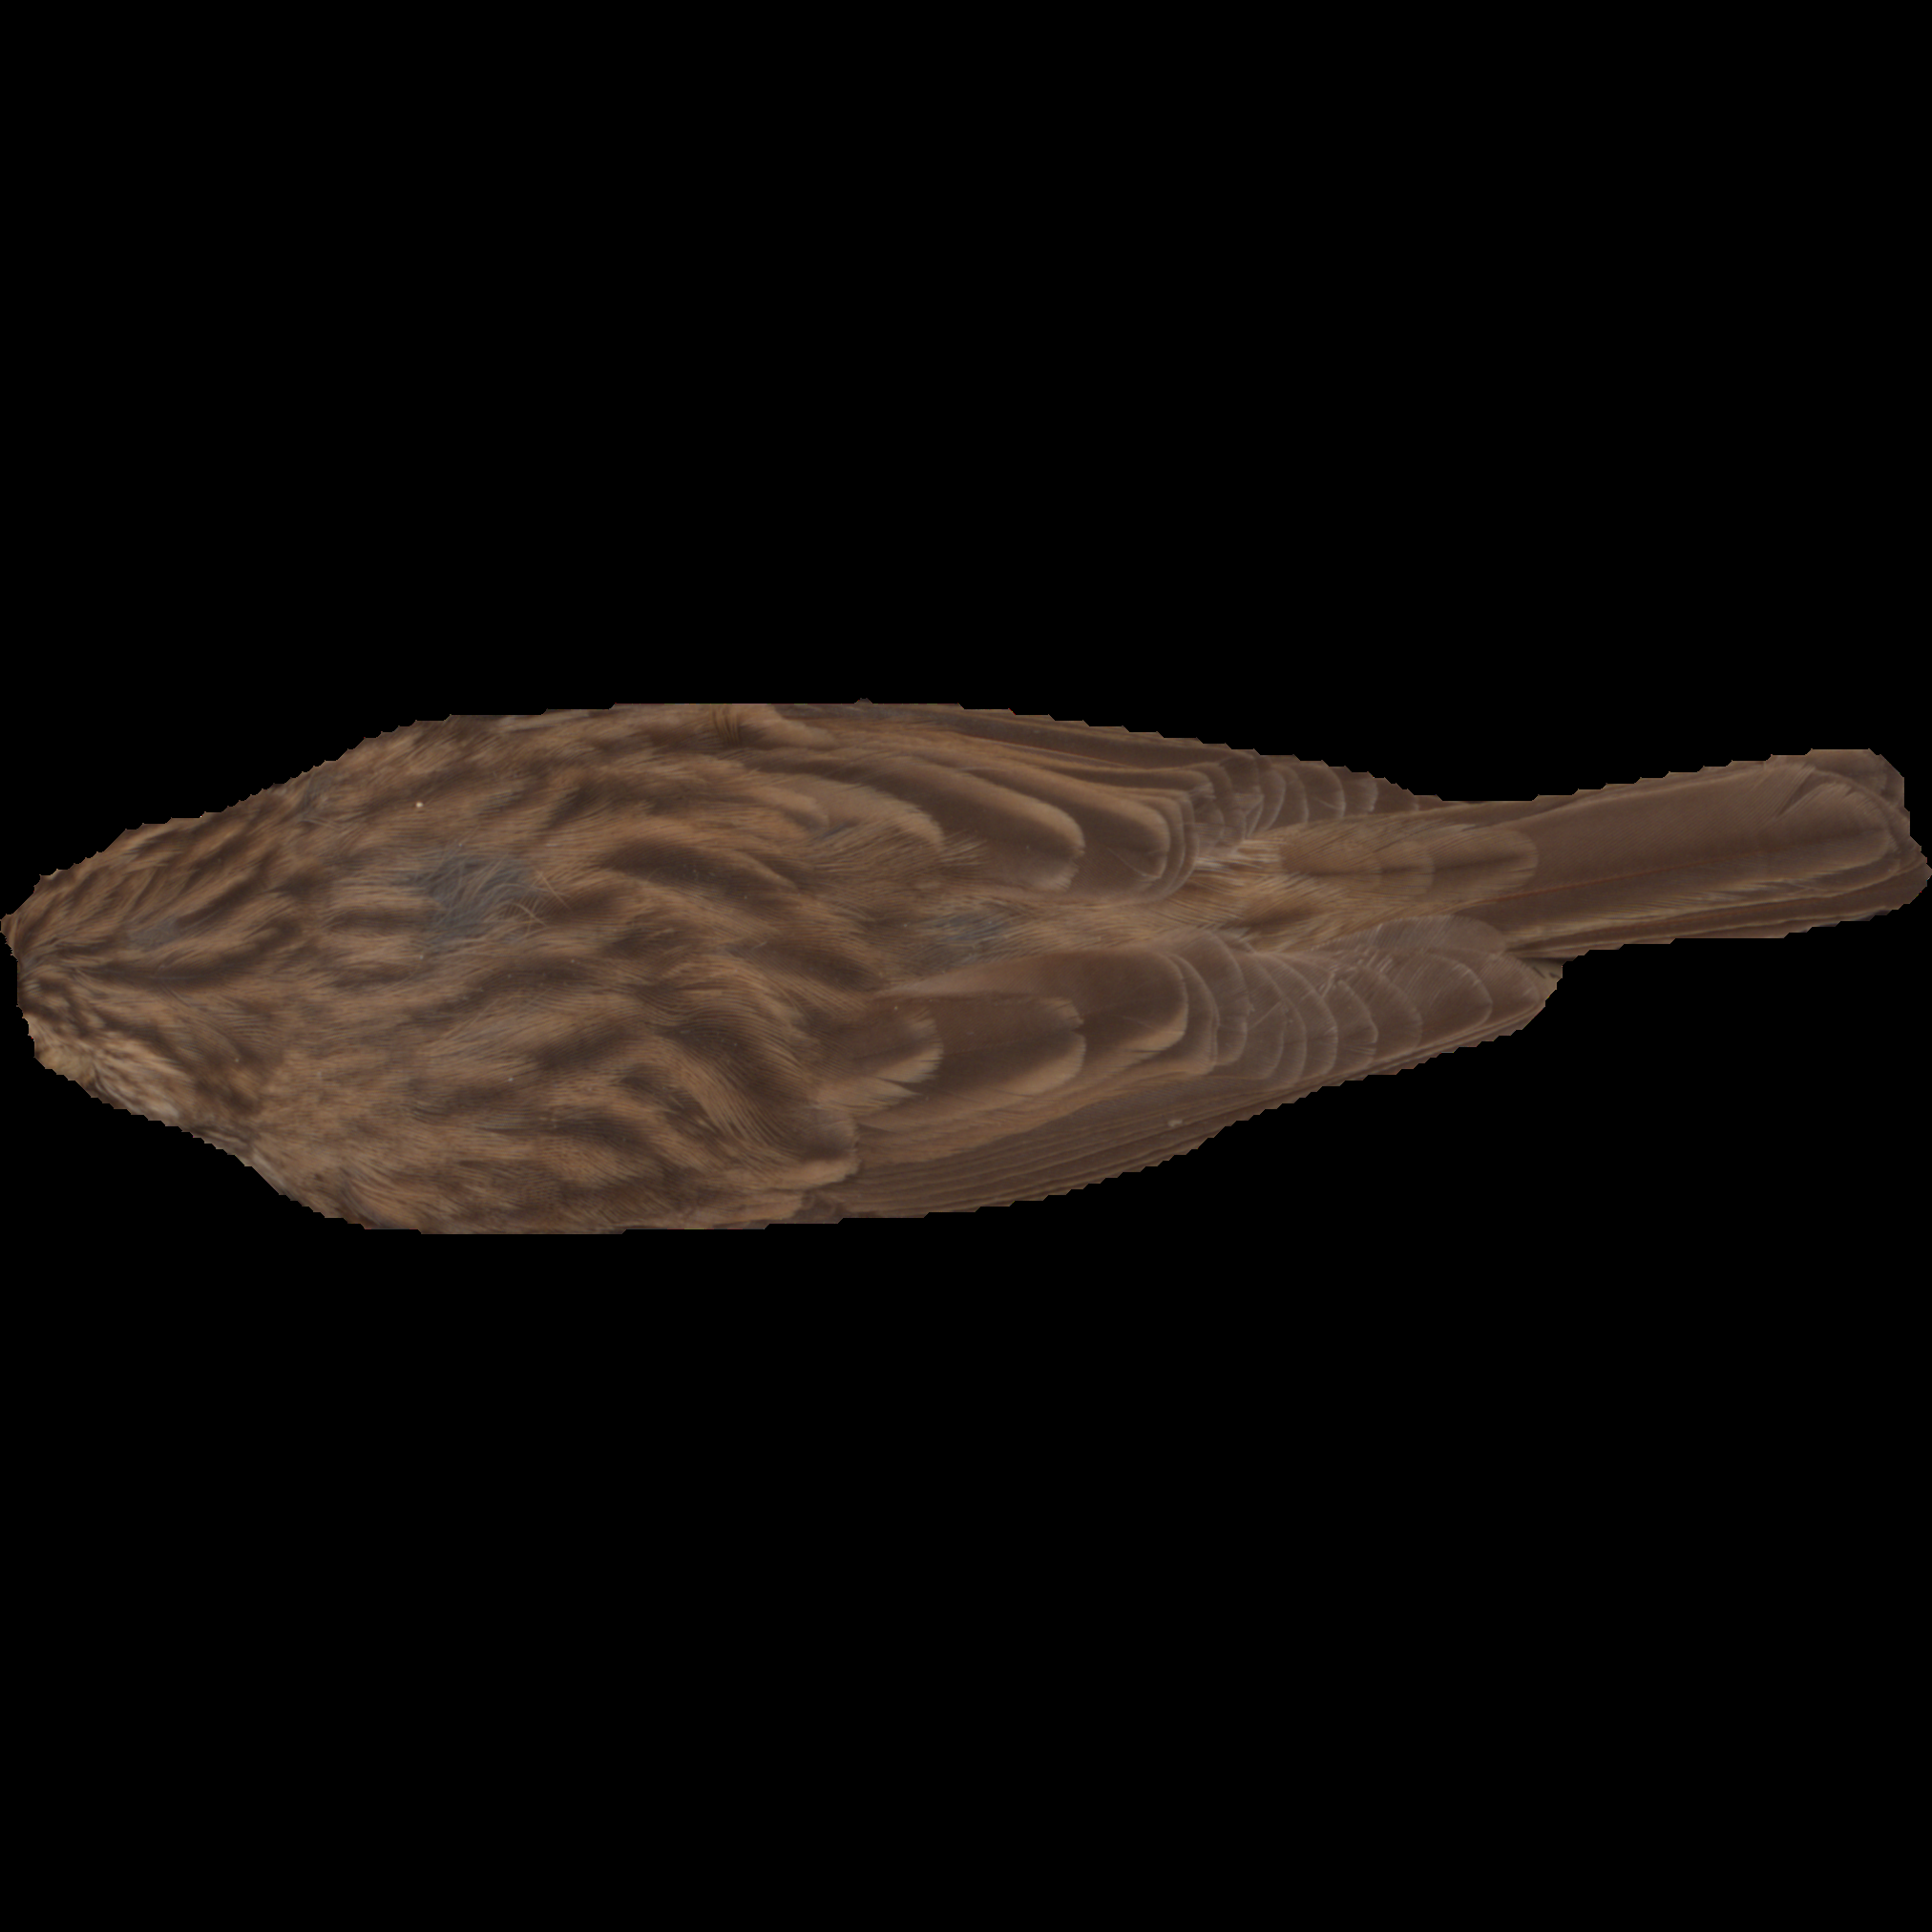

In [18]:
im2 = Image.fromarray(np.uint8(im))
im2

In [36]:
meta_img = df[df["stem"]=="Carpodacus_pulcherrimus_5_F_Back_Vis_G095156"]
coord = meta_img["meta"].values
coord

array([array([[ 128, 1140,  850],
              [ 128,  941, 1376],
              [ 128,  841, 1668],
              [ 128, 1044,  185],
              [ 128,  859,  336],
              [ 128,  977, 1037],
              [ 128, 1148,  362],
              [ 128,  744,  880],
              [ 224,  868, 1130],
              [ 224, 1031,  812],
              [ 224,  848, 1376],
              [ 224,  911,  661],
              [ 224,  987,  424],
              [ 224, 1002,  305],
              [ 224, 1040,  327],
              [ 224, 1034,  771]], dtype=int32)], dtype=object)

In [44]:
attention = meta_img["attention"].values
attention

array([array([0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625,
              0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625, 0.0625],
             dtype=float32)                                                   ],
      dtype=object)

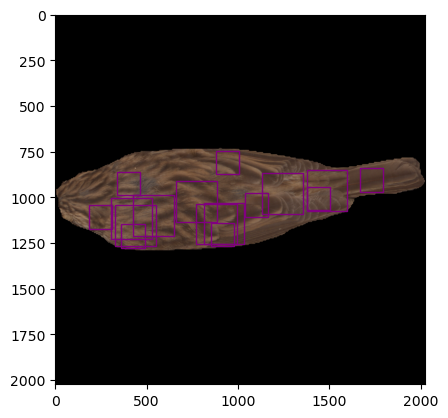

In [42]:
import matplotlib.pyplot as plt 
from matplotlib.patches import Rectangle
from matplotlib import patches 

fig, ax = plt.subplots()
for c in coord[0] : 
    square = patches.Rectangle((c[2],c[1]), c[0], c[0], edgecolor='purple', facecolor='none')
    ax.add_patch(square)

plt.imshow(im2)